# Support Vector Machine Classification Using the Iris Dataset

**Experiment:** Binary Setosa vs Non-Setosa classification with a linear SVM, followed by three-class classification using Linear, Polynomial and RBF kernels.

This notebook follows the supplied experiment record. It uses the built-in Scikit-learn Iris dataset; no external dataset file is required.

**Reproducibility:** Both experiments use an 80:20 stratified train/test split with `random_state=42`. Each scaler is fitted on training data only to avoid test-data leakage.

## 1. Import required libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay
)

%matplotlib inline
plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["axes.grid"] = True

## 2. Load and inspect the Iris dataset

In [2]:
# Load Iris once and inspect its features and class labels
iris = load_iris()
X = iris.data
y = iris.target

print("Dataset dimensions:", X.shape)
print("Feature names:", list(iris.feature_names))
print("Species names:", list(iris.target_names))
print("\\nClass counts:")
for class_id, species in enumerate(iris.target_names):
    print(f"{species}: {np.sum(y == class_id)}")

Dataset dimensions: (150, 4)
Feature names: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Species names: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]
\nClass counts:
setosa: 50
versicolor: 50
virginica: 50


## Part A — Linear SVM: Setosa vs Non-Setosa

Use only petal length and petal width. Setosa is labelled `0`; Versicolor and Virginica are combined as Non-Setosa and labelled `1`.

In [3]:
# Select petal length and petal width (columns 2 and 3)
X_binary = X[:, [2, 3]]
y_binary = (y != 0).astype(int)  # Setosa=0, Non-Setosa=1

X_train_a, X_test_a, y_train_a, y_test_a = train_test_split(
    X_binary, y_binary,
    test_size=0.20,
    random_state=42,
    stratify=y_binary
)

# Fit scaler only on training data
scaler_a = StandardScaler()
X_train_a_scaled = scaler_a.fit_transform(X_train_a)
X_test_a_scaled = scaler_a.transform(X_test_a)

print("Part A training samples:", len(X_train_a))
print("Part A testing samples:", len(X_test_a))
print("Training class counts (Setosa, Non-Setosa):",
      np.bincount(y_train_a))
print("Testing class counts (Setosa, Non-Setosa):",
      np.bincount(y_test_a))

Part A training samples: 120
Part A testing samples: 30
Training class counts (Setosa, Non-Setosa): [40 80]
Testing class counts (Setosa, Non-Setosa): [10 20]


## 3. Train and evaluate the binary linear SVM

In [4]:
binary_svm = SVC(kernel="linear", C=1.0)
binary_svm.fit(X_train_a_scaled, y_train_a)

y_pred_a = binary_svm.predict(X_test_a_scaled)

print("Binary classification accuracy:",
      f"{accuracy_score(y_test_a, y_pred_a):.4f}")
print("\\nBinary classification report:")
print(classification_report(
    y_test_a, y_pred_a,
    labels=[0, 1],
    target_names=["Setosa", "Non-Setosa"],
    zero_division=0
))
print("Confusion matrix:")
print(confusion_matrix(y_test_a, y_pred_a))
print("\\nSupport vectors per class [Setosa, Non-Setosa]:",
      binary_svm.n_support_)
print("Total support vectors:", len(binary_svm.support_vectors_))

Binary classification accuracy: 1.0000
\nBinary classification report:
              precision    recall  f1-score   support

      Setosa       1.00      1.00      1.00        10
  Non-Setosa       1.00      1.00      1.00        20

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30

Confusion matrix:
[[10  0]
 [ 0 20]]
\nSupport vectors per class [Setosa, Non-Setosa]: [2 2]
Total support vectors: 4


## 4. Plot the decision boundary, margins and support vectors

The decision function is `f(z) = wᵀz + b`. The decision boundary is `f(z)=0`, and the canonical margin lines are `f(z)=-1` and `f(z)=+1`. Support vectors are circled. Axes are in standardized feature coordinates.

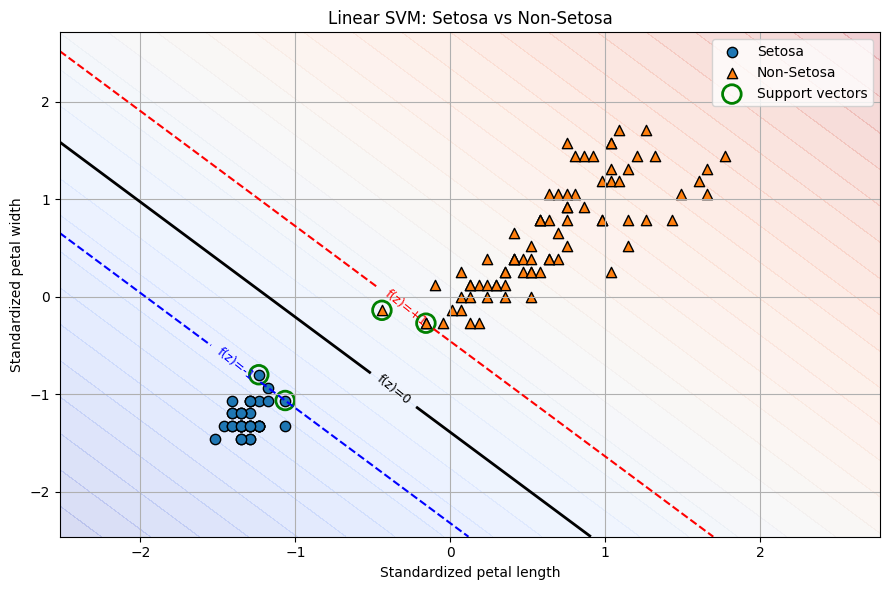

In [5]:
# Create a grid in standardized feature space
x_min, x_max = X_train_a_scaled[:, 0].min() - 1, X_train_a_scaled[:, 0].max() + 1
y_min, y_max = X_train_a_scaled[:, 1].min() - 1, X_train_a_scaled[:, 1].max() + 1
xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 500),
    np.linspace(y_min, y_max, 500)
)
grid = np.c_[xx.ravel(), yy.ravel()]
decision_values = binary_svm.decision_function(grid).reshape(xx.shape)

plt.figure(figsize=(9, 6))
plt.contourf(xx, yy, decision_values, levels=30, cmap="coolwarm", alpha=0.20)
contours = plt.contour(
    xx, yy, decision_values,
    levels=[-1, 0, 1],
    colors=["blue", "black", "red"],
    linestyles=["--", "-", "--"],
    linewidths=[1.5, 2, 1.5]
)
plt.clabel(contours, inline=True, fontsize=9, fmt={-1: "f(z)=-1", 0: "f(z)=0", 1: "f(z)=+1"})

for label, name, color, marker in [
    (0, "Setosa", "tab:blue", "o"),
    (1, "Non-Setosa", "tab:orange", "^")
]:
    mask = y_train_a == label
    plt.scatter(
        X_train_a_scaled[mask, 0], X_train_a_scaled[mask, 1],
        c=color, marker=marker, label=name, edgecolors="black", s=55
    )

# Highlight support vectors
sv = binary_svm.support_vectors_
plt.scatter(
    sv[:, 0], sv[:, 1],
    s=180, facecolors="none", edgecolors="green",
    linewidths=2, label="Support vectors"
)

plt.xlabel("Standardized petal length")
plt.ylabel("Standardized petal width")
plt.title("Linear SVM: Setosa vs Non-Setosa")
plt.legend()
plt.tight_layout()
plt.show()

## 5. Weight vector, intercept and total margin width

In [6]:
# For a binary linear SVM, coef_ gives the weight vector
w = binary_svm.coef_[0]
b = binary_svm.intercept_[0]
w_norm = np.linalg.norm(w)
margin_width = 2 / w_norm

print("Weight vector (w):", w)
print("Intercept (b):", b)
print("||w||:", w_norm)
print("Distance from boundary to either margin:", 1 / w_norm)
print("Total margin width (2 / ||w||):", margin_width)
print("\\nNote: Margin distances are in standardized feature space, not centimetres.")

Weight vector (w): [1.26649723 1.07262117]
Intercept (b): 1.4887142374399387
||w||: 1.6596781061193557
Distance from boundary to either margin: 0.602526475653879
Total margin width (2 / ||w||): 1.205052951307758
\nNote: Margin distances are in standardized feature space, not centimetres.


## Part B — Three-class Iris classification with three kernels

Use all four features and the original three species. A new stratified split and a new training-only scaler are required because Part B has different features and labels. The dataset is **not** loaded again.

In [7]:
X_train_b, X_test_b, y_train_b, y_test_b = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

scaler_b = StandardScaler()
X_train_b_scaled = scaler_b.fit_transform(X_train_b)
X_test_b_scaled = scaler_b.transform(X_test_b)

print("Part B training samples:", len(X_train_b))
print("Part B testing samples:", len(X_test_b))
print("Training class counts:", np.bincount(y_train_b))
print("Testing class counts:", np.bincount(y_test_b))

Part B training samples: 120
Part B testing samples: 30
Training class counts: [40 40 40]
Testing class counts: [10 10 10]


## 6. Train Linear, Polynomial and RBF SVMs and compare results

In [8]:
# Required kernel configurations from the experiment record
models = {
    "Linear": SVC(kernel="linear", C=1.0),
    "Polynomial": SVC(kernel="poly", degree=3, coef0=0,
                      gamma="scale", C=1.0),
    "RBF": SVC(kernel="rbf", gamma="scale", C=1.0)
}

accuracies = {}
predictions = {}

for kernel_name, model in models.items():
    model.fit(X_train_b_scaled, y_train_b)
    y_pred = model.predict(X_test_b_scaled)
    predictions[kernel_name] = y_pred
    accuracies[kernel_name] = accuracy_score(y_test_b, y_pred)

    print("=" * 65)
    print(f"{kernel_name} SVM")
    print(f"Test accuracy: {accuracies[kernel_name]:.4f}")
    print("\\nClassification report:")
    print(classification_report(
        y_test_b, y_pred,
        labels=[0, 1, 2],
        target_names=iris.target_names,
        zero_division=0
    ))
    print("Confusion matrix:")
    print(confusion_matrix(y_test_b, y_pred))

Linear SVM
Test accuracy: 1.0000
\nClassification report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00        10
   virginica       1.00      1.00      1.00        10

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30

Confusion matrix:
[[10  0  0]
 [ 0 10  0]
 [ 0  0 10]]
Polynomial SVM
Test accuracy: 0.9000
\nClassification report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.77      1.00      0.87        10
   virginica       1.00      0.70      0.82        10

    accuracy                           0.90        30
   macro avg       0.92      0.90      0.90        30
weighted avg       0.92      0.90      0.90        30

Confusion matrix:
[[10  0  0]
 [ 0 10  0]
 [ 0  3  7]]
RBF SVM


## 7. Bar graph: test accuracy comparison

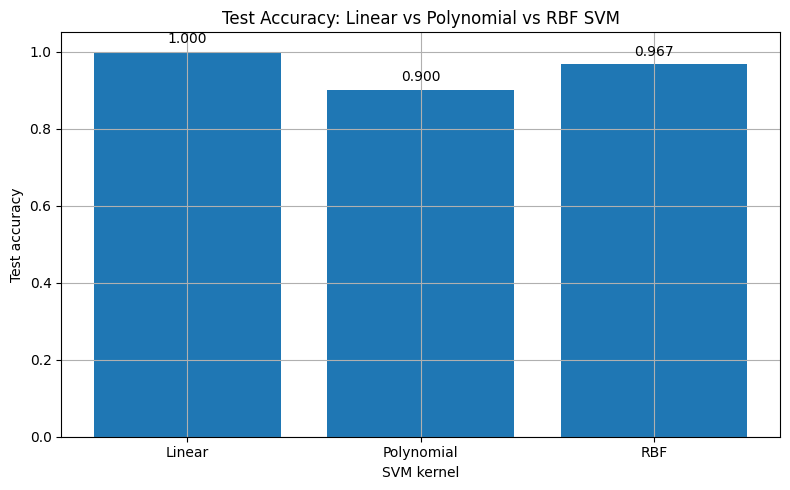

Accuracy summary:
Linear: 1.0000
Polynomial: 0.9000
RBF: 0.9667


In [9]:
plt.figure(figsize=(8, 5))
bars = plt.bar(list(accuracies.keys()), list(accuracies.values()))
plt.ylim(0, 1.05)
plt.ylabel("Test accuracy")
plt.xlabel("SVM kernel")
plt.title("Test Accuracy: Linear vs Polynomial vs RBF SVM")

for bar, value in zip(bars, accuracies.values()):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.015,
        f"{value:.3f}",
        ha="center", va="bottom"
    )

plt.tight_layout()
plt.show()

print("Accuracy summary:")
for name, value in accuracies.items():
    print(f"{name}: {value:.4f}")

## 8. Analysis questions

**1. Compare Linear, Polynomial and RBF kernels.**  
- **Linear:** Uses a straight separating hyperplane and is suitable when classes are approximately linearly separable. It is simple and computationally efficient.
- **Polynomial:** Uses a polynomial kernel; here degree is 3, `coef0=0`, `gamma="scale"` and `C=1.0`. It can model curved relationships and feature interactions.
- **RBF:** Uses a Gaussian radial basis function kernel with `gamma="scale"` and `C=1.0`. It can form flexible nonlinear decision boundaries and is useful when the class relationship is not linear.

The best kernel for this experiment should be identified from the **actual test accuracies and confusion matrices printed above**, not assumed in advance.

**2. Why is the Maximum Margin important?**  
The maximum-margin principle selects a separating boundary that leaves the largest possible distance to the closest training points. A wider margin can improve generalization to unseen data. In a soft-margin SVM, the parameter `C` balances margin width against margin violations: smaller `C` gives stronger regularization and usually permits more violations; larger `C` penalizes violations more strongly and can produce a narrower margin.

**3. When should kernel methods be preferred?**  
Kernel methods are useful when the relationship between features and classes is nonlinear and a straight hyperplane is not adequate. Polynomial and RBF kernels implicitly map data into a higher-dimensional feature space, allowing nonlinear separation without explicitly computing that mapping. The kernel should be selected using validation or test performance and awareness of overfitting risk.

## 9. Conclusion

Complete the conclusion after running the notebook. Include:
- the observed binary classification accuracy;
- the calculated total margin width in standardized feature space;
- the Linear, Polynomial and RBF three-class test accuracies; and
- what the comparison suggests for this Iris split.

**Important:** Results can vary if the split, preprocessing, or model settings are changed. This notebook fixes the settings specified in the supplied experiment record.